In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files
from sklearn.decomposition import PCA

df = pd.read_csv('customers.csv').drop(columns=['Row', 'CustomerId'])
df = df.fillna(df.mean())
X = ((df - df.mean()) / df.std()).values

In [7]:
def sq_dists(X, C):
    return ((X[:, None, :] - C[None, :, :]) ** 2).sum(-1)

def kmeans(X, k, seed=0, iters=50):
    rng = np.random.default_rng(seed)
    C = X[rng.choice(len(X), k, replace=False)]
    for _ in range(iters):
        labels = sq_dists(X, C).argmin(1)
        Cnew = np.array([X[labels == j].mean(0) if (labels == j).any() else C[j]
                         for j in range(k)])
        if np.allclose(Cnew, C): break
        C = Cnew
    D = sq_dists(X, C); labels = D.argmin(1)
    return labels, D[range(len(X)), labels].sum()

def kmedoids(X, k, seed=0, iters=50):
    rng = np.random.default_rng(seed)
    med = rng.choice(len(X), k, replace=False)
    for _ in range(iters):
        labels = sq_dists(X, X[med]).argmin(1)
        new = []
        for j in range(k):
            idx = np.where(labels == j)[0]
            if len(idx) == 0: new.append(med[j]); continue
            D = sq_dists(X[idx], X[idx])
            new.append(idx[D.sum(1).argmin()])
        if set(new) == set(med.tolist()): break
        med = np.array(new)
    D = sq_dists(X, X[med]); labels = D.argmin(1)
    return labels, D[range(len(X)), labels].sum()

def add_noise(X, frac, seed=42):
    rng = np.random.default_rng(seed)
    Xn = X.copy()
    n = int(round(len(X) * frac))
    if n == 0: return Xn
    idx = rng.choice(len(X), n, replace=False)
    mask = rng.random((n, X.shape[1])) < 0.3
    mask[range(n), rng.integers(0, X.shape[1], n)] = True
    Xn[idx] += mask * rng.uniform(-3, 3, (n, X.shape[1]))
    return Xn

        Age  Education  YearsEmployed    Income  CardDebt  OtherDebt  \
0  0.742478   0.311939      -0.378567 -0.718036 -0.683409  -0.590142   
1  1.488614  -0.765898       2.572207  1.383510  1.413641   1.512072   
2 -0.252369   0.311939       0.211588  0.267875  2.132885   0.801232   
3 -0.749793   0.311939      -0.673644 -0.718036 -0.421395  -0.754023   
4  1.488614  -0.765898       3.309900  5.353097  3.636759   1.715084   
5  0.618122  -0.765898       2.129591  0.890555 -0.272278   1.398208   
6  0.369410   0.311939      -0.673644  0.241930 -0.533821  -0.772265   
7  0.866834   1.389776      -1.263799  0.449490 -0.610497   0.254863   
8 -1.122861  -0.765898      -0.526106 -0.743981 -0.471258  -0.254141   
9  1.488614   1.389776       2.129591  1.772685 -0.434566   0.255451   

   Defaulted  DebtIncomeRatio  cluster  
0  -0.655217        -0.576186        2  
1  -0.655217         0.391156        3  
2   1.851077         1.596614        0  
3  -0.655217        -0.576186        2  
4 

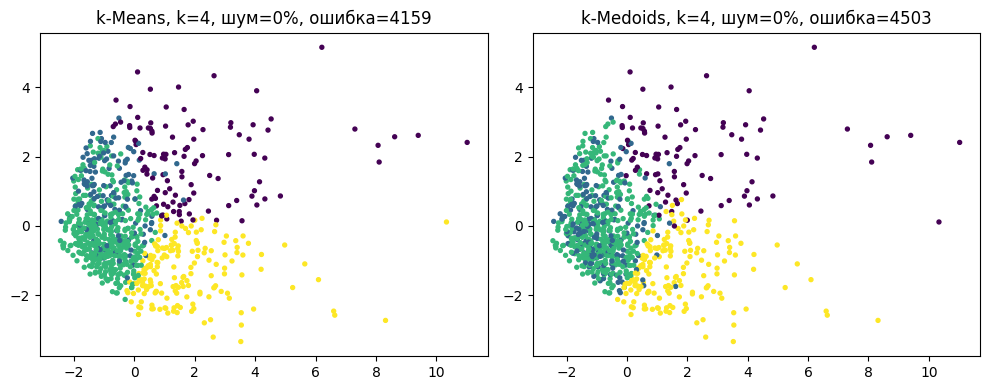

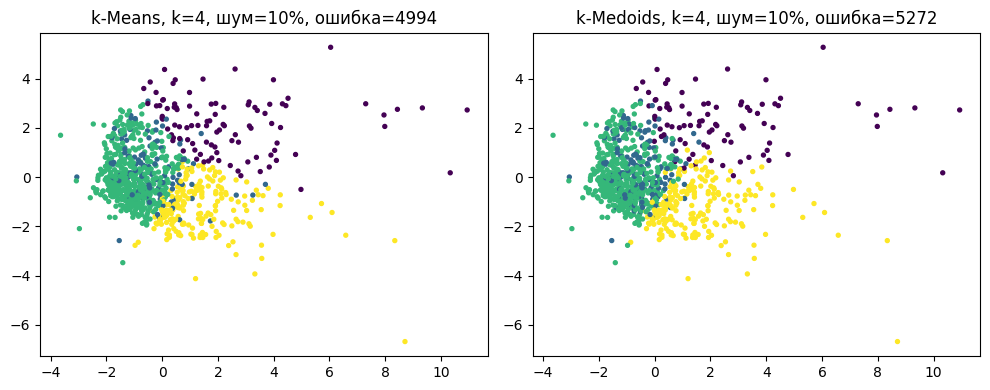

In [8]:
def show_clusters(X, k, frac=0.0):
    Xn = add_noise(X, frac)
    P = PCA(n_components=2).fit_transform(Xn)
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    for ax, (name, alg) in zip(axes, [('k-Means', kmeans), ('k-Medoids', kmedoids)]):
        labels, err = alg(Xn, k)
        ax.scatter(P[:, 0], P[:, 1], c=labels, cmap='viridis', s=8)
        ax.set_title(f'{name}, k={k}, шум={frac:.0%}, ошибка={err:.0f}')
    plt.tight_layout(); plt.show()

labels, error = kmeans(X, 4)
res = pd.DataFrame(X, columns=df.columns).assign(cluster=labels)
print(res.head(10)); print('ошибка:', round(error, 1))
res.to_csv('result.csv', index=False)

show_clusters(X, 4)
show_clusters(X, 4, 0.10)

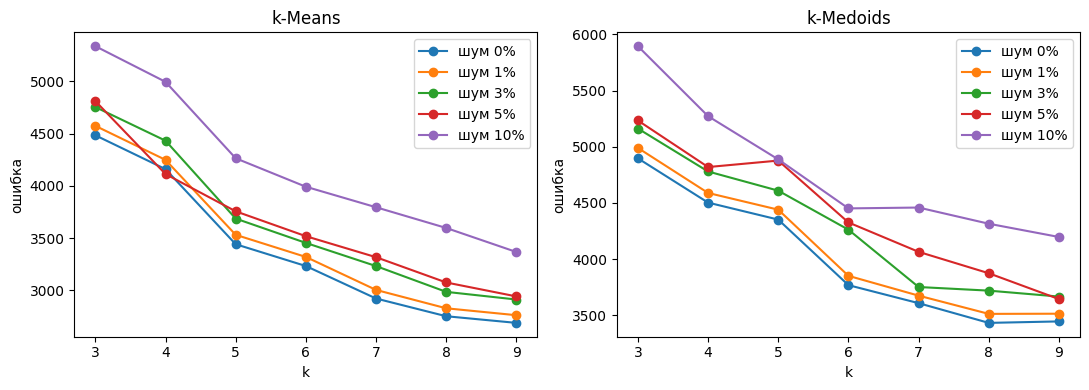

In [9]:
ks = range(3, 10)
fracs = [0.0, 0.01, 0.03, 0.05, 0.10]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, alg) in zip(axes, [('k-Means', kmeans), ('k-Medoids', kmedoids)]):
    for f in fracs:
        Xn = add_noise(X, f)
        ax.plot(list(ks), [alg(Xn, k)[1] for k in ks], marker='o', label=f'шум {f:.0%}')
    ax.set(xlabel='k', ylabel='ошибка', title=name); ax.legend()
plt.tight_layout(); plt.show()